# 서포트 벡터 머신 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/ml1/week02/2_svm/lab/svm.ipynb)

가장 넓은 길을 내는 분류기. 마진과 서포트 벡터를 확인하고, 학습 방법을 직접 짜 보고, 소프트 마진을 본다. (커널 · 실제 데이터는 다음 차시 `3_svm_kernel` 실습)

- **파트 1**: 슬라이드의 점 20개를 z-score 하고: 마진 m 0.67 (길 폭 1.34), 서포트 벡터 3개
- **파트 2**: 슬라이드의 학습 방법을 직접 짜서 sklearn 과 비교
- **파트 3**: 이상치 하나 넣고 소프트 마진

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

## 슬라이드의 예시 데이터

원래 값에서 축마다 평균을 빼고 표준편차로 나눈다 (z-score). 슬라이드의 점은 이 값을 소수 첫째 자리로 반올림한 것.

In [ ]:
# Same example as the slides: 10 red (+1) and 10 blue (-1) points, raw values
X_raw = np.array([[5.9, 6.8], [5.3, 8.0], [6.3, 6.2], [6.1, 9.2], [5.5, 7.4], [6.6, 8.6], [5.7, 5.6], [5.5, 9.8], [6.6, 6.8], [4.8, 8.9],   # red
              [4.4, 1.1], [3.8, 1.7], [4.6, 2.3], [4.0, 3.2], [3.6, 0.5], [4.4, 3.8], [5.1, 1.7], [3.4, 3.2], [4.8, 0.8], [3.7, 4.4]])  # blue
y = np.array([1] * 10 + [-1] * 10)
X = None  # TODO: z-score each column, round to 1 decimal
print("mean", X.mean(0).round(2), " std", X.std(0).round(2))

def plot_svm(model, X, y, ax=None, title=""):
    ax = ax or plt.gca()
    gx, gy = np.meshgrid(np.linspace(-2.2, 2.2, 200), np.linspace(-2.2, 2.2, 200))
    Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contour(gx, gy, Z, levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm_r")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="gold", linewidths=2)
    ax.set_aspect("equal"); ax.set_title(title)

**예상 결과**

```
mean [0.01 0.  ]  std [0.99 1.01]
```

## 파트 1. 마진과 서포트 벡터

`C` 를 아주 크게 하면 하드 마진(길 안에 점 없음). sklearn 이 주는 $\mathbf{w}, b$ 를 $\lVert\mathbf{w}\rVert$ 로 나눠 길이 1 로 맞추면 값 = 거리, 마진 $m$ = 가장 가까운 점의 값, 길 폭 $= 2m$.

In [ ]:
model = SVC(kernel="linear", C=1e6).fit(X, y)
n = np.linalg.norm(model.coef_[0])
w, b = model.coef_[0] / n, model.intercept_[0] / n          # scale so that ||w|| = 1 (value = distance)
margin = None  # TODO: m = distance to the nearest point
print("w =", w.round(3), " b =", round(b, 3), " m =", round(margin, 2), " street width =", round(2 * margin, 2))
print("support vectors:", model.support_vectors_.tolist())

X_moved = X.copy()
X_moved[14] = [-2.1, -1.8]                                # move a far-away blue point
model2 = SVC(kernel="linear", C=1e6).fit(X_moved, y)
print("w after moving a far point:", model2.coef_[0].round(3))
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
plot_svm(model, X, y, axs[0], "original"); plot_svm(model2, X_moved, y, axs[1], "far point moved"); plt.show()

**예상 결과**

```
w = [0.707 0.707]  b = 0.035  m = 0.67  street width = 1.34
support vectors: [[-0.6, -0.4], [0.1, -1.1], [0.7, 0.2]]
w after moving a far point: [1.052 1.052]
```

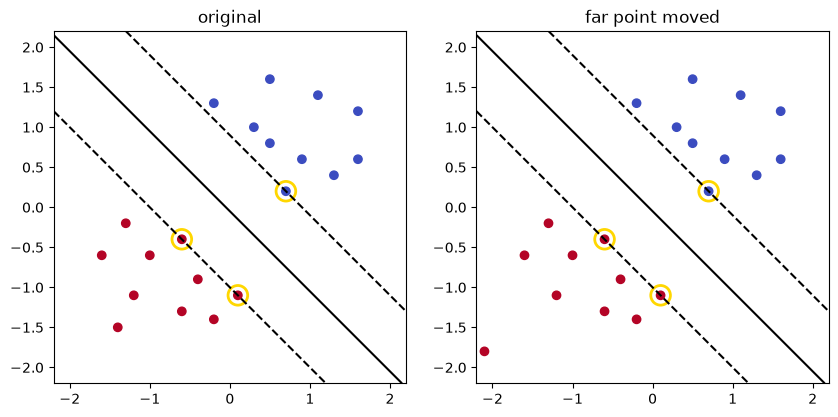

## 파트 2. 슬라이드의 학습 방법을 직접 짜서 sklearn 과 비교

슬라이드 "학습 한 걸음": 값이 가장 작은 점이 민다 → $\mathbf{w}$ 만 길이로 나눠 1 로 맞춘다 ($b$ 는 그대로). 2만 걸음 뒤 sklearn 답과 같은지 확인한다.

In [ ]:
def train_maxmin(X, y, steps=20000, lr0=0.05):
    w, b = np.zeros(X.shape[1]), 0.0
    for t in range(1, steps + 1):
        v = y * (X @ w + b)                                # value = distance to the line (||w|| = 1)
        k = v <= v.min() + 1e-9                            # the closest point(s) push; at the start all 20 tie
        eta = lr0 / np.sqrt(t)
        w = None  # TODO: w' = w + eta * sum(y_k x_k)
        b = b + eta * y[k].sum()
        n = np.linalg.norm(w)
        if n > 0:
            w = w / n                                      # only w is rescaled to length 1; b stays
    return w, b

w_mine, b_mine = train_maxmin(X, y)
m_mine = (y * (X @ w_mine + b_mine)).min()
print("mine   : w =", w_mine.round(3), " b =", round(b_mine, 3), " m =", round(m_mine, 3))
print("sklearn: w =", w.round(3), " b =", round(b, 3), " m =", round(margin, 3))
print("angle between the two w (deg):", round(np.degrees(np.arccos(w_mine @ w / np.linalg.norm(w_mine))), 3))

**예상 결과**

```
mine   : w = [0.707 0.707]  b = 0.036  m = 0.671
sklearn: w = [0.707 0.707]  b = 0.035  m = 0.672
angle between the two w (deg): 0.007
```

## 파트 3. 소프트 마진

빨간 이상치 하나를 파란 쪽에 넣는다. sklearn 의 `C` 는 슬라이드의 λ 와 방향이 반대: C 가 크면 좁은 길, 작으면 넓은 길.

In [ ]:
# Soft margin: add one red outlier inside the blue group
X_out = np.r_[X, [[-0.2, -0.6]]]; y_out = np.r_[y, [1]]
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, C in zip(axs, [100, 3, 0.3]):
    m = SVC(kernel="linear", C=C).fit(X_out, y_out)
    n_sv = None  # TODO: number of support vectors
    plot_svm(m, X_out, y_out, ax, f"C={C}: m {1 / np.linalg.norm(m.coef_[0]):.2f}, {n_sv} SVs")   # street edge: distance 1/||coef|| after scaling w to length 1
plt.show()

**예상 결과**

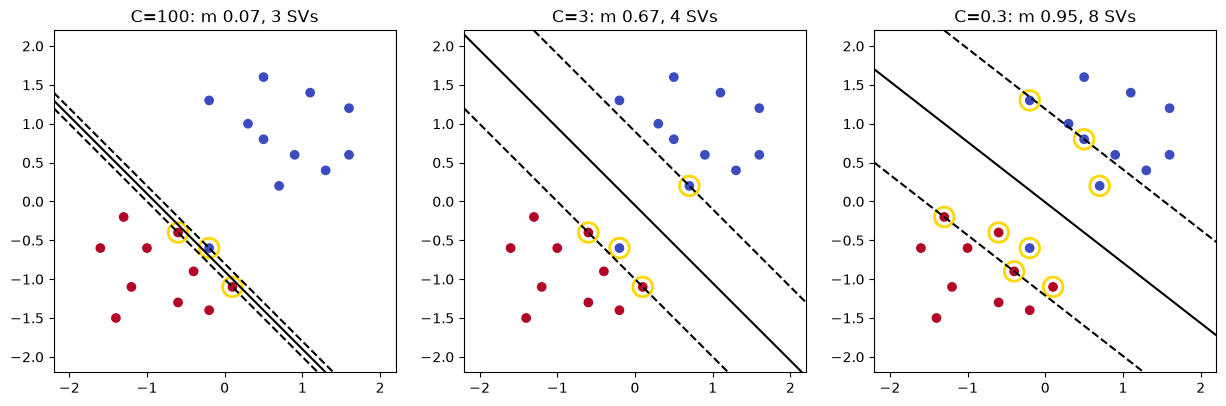

**확인 질문**
1. 파트 1 에서 서포트 벡터 하나를 옮기면 w 가 바뀌는가? 직접 해 보자.
2. 파트 2 에서 `w` 만 나누지 않고 `b` 까지 나누면 어떻게 되나? 바꿔서 sklearn 과 비교해 보자.
3. 파트 3 에서 C 를 줄일수록 서포트 벡터 수는 어떻게 되나? 왜 그럴까?